In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
import os

In [ ]:
from google.colab import files
import pandas as pd

print("Please upload your 'WA_Fn-UseC_-HR-Employee-Attrition.csv' file:")
uploaded = files.upload()

# Automatically get the filename of the uploaded file and read it into pandas
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print('\n--- Dataset Sample ---')
print(df.head(), '\n')

Please upload your 'WA_Fn-UseC_-HR-Employee-Attrition.csv' file:


Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition (2).csv

--- Dataset Sample ---
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Med

In [ ]:
X = df.drop(columns=['Attrition'])
y = df['Attrition'].apply(lambda x: 1 if str(x).strip() == 'Yes' else 0)

In [ ]:
numeric_features = [
    'Age',
    'MonthlyIncome',
    'JobSatisfaction',
    'YearsAtCompany',
]
categorical_features = ['OverTime', 'Department']

# Preprocessing pipeline for numeric data: Impute missing values & scale
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

# Preprocessing pipeline for categorical data: Impute missing values & one-hot encode
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        (
            'encoder',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
        ),
    ]
)

# Combine preprocessing steps into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ]
)

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
}

evaluation_results = {}

print('--- Model Evaluation Metrics ---')
for name, model in models.items():
  clf_pipeline = Pipeline(
      steps=[('preprocessor', preprocessor), ('classifier', model)]
  )

  clf_pipeline.fit(X_train, y_train)
  y_pred = clf_pipeline.predict(X_test)
  f1 = f1_score(y_test, y_pred)

  evaluation_results[name] = {
      'pipeline': clf_pipeline,
      'y_pred': y_pred,
      'f1_score': f1,
  }

  print(f'\nModel: {name}')
  print(f'F1 Score: {f1:.4f}')
  print('Classification Report:')
  print(classification_report(y_test, y_pred))
  print('-' * 50)

--- Model Evaluation Metrics ---

Model: Logistic Regression
F1 Score: 0.3667
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.99      0.93       247
           1       0.85      0.23      0.37        47

    accuracy                           0.87       294
   macro avg       0.86      0.61      0.65       294
weighted avg       0.87      0.87      0.84       294

--------------------------------------------------

Model: Decision Tree
F1 Score: 0.2692
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84       247
           1       0.25      0.30      0.27        47

    accuracy                           0.74       294
   macro avg       0.55      0.56      0.56       294
weighted avg       0.76      0.74      0.75       294

--------------------------------------------------

Model: Random Forest
F1 Score: 0.2286
Classification Report:
              preci

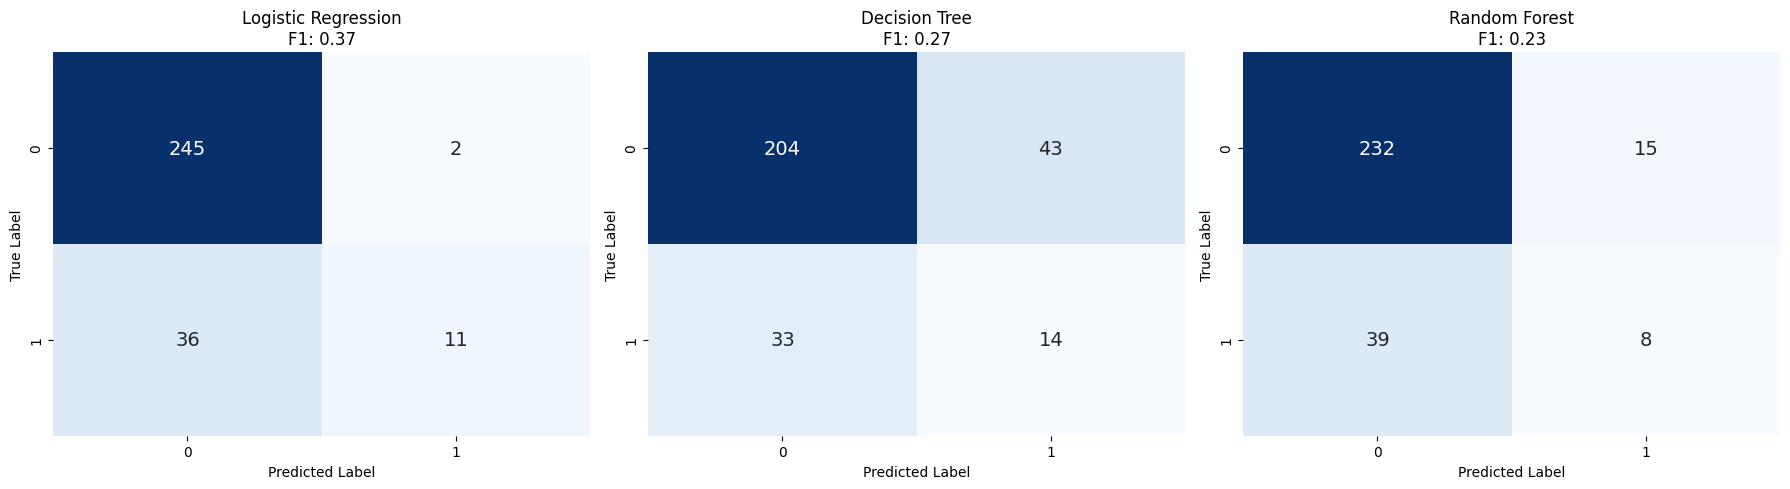

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (name, res) in enumerate(evaluation_results.items()):
  cm = confusion_matrix(y_test, res['y_pred'])
  sns.heatmap(
      cm,
      annot=True,
      fmt='d',
      cmap='Blues',
      ax=axes[idx],
      cbar=False,
      annot_kws={'size': 14},
  )
  axes[idx].set_title(f'{name}\nF1: {res["f1_score"]:.2f}')
  axes[idx].set_xlabel('Predicted Label')
  axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()

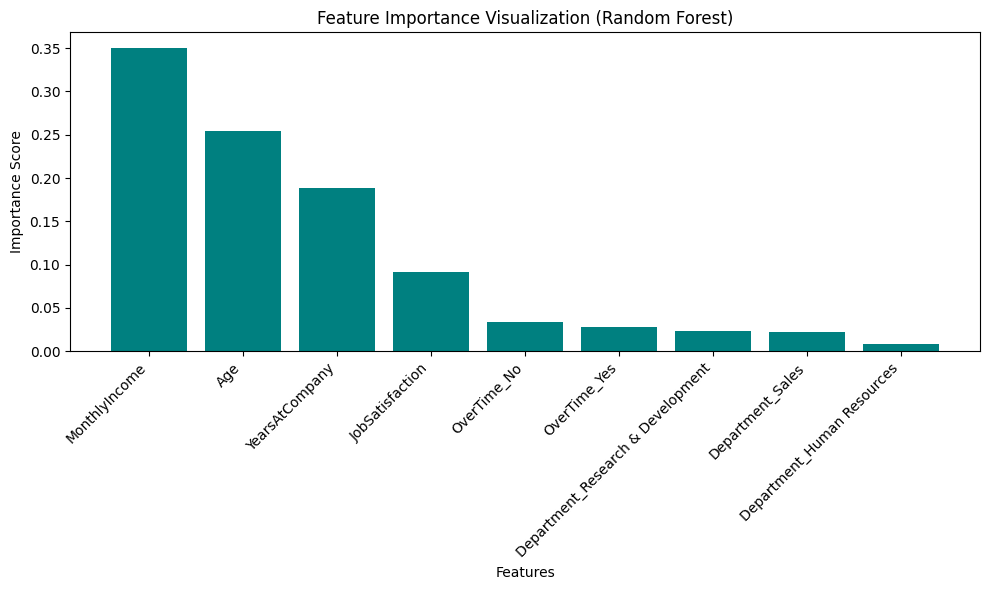

In [ ]:
rf_pipeline = evaluation_results['Random Forest']['pipeline']
cat_encoder = (
    rf_pipeline.named_steps['preprocessor']
    .named_transformers_['cat']
    .named_steps['encoder']
)
encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + encoded_cat_features

importances = rf_pipeline.named_steps['classifier'].feature_importances_
sorted_indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title('Feature Importance Visualization (Random Forest)')
plt.bar(
    range(len(importances)),
    importances[sorted_indices],
    align='center',
    color='teal',
)
plt.xticks(
    range(len(importances)),
    [all_features[i] for i in sorted_indices],
    rotation=45,
    ha='right',
)
plt.ylabel('Importance Score')
plt.xlabel('Features')
plt.tight_layout()
plt.show()

2nd OEL Task

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [ ]:
from google.colab import files
import pandas as pd

print("Please upload your 'Heath Risk classification.csv' file:")
uploaded = files.upload()

# Automatically get the filename of the uploaded file and read it into pandas
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

df.columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome',
]

print('--- Dataset Sample ---')
print(df.head(), '\n')

Please upload your 'Heath Risk classification.csv' file:


Saving pima-indians-diabetes.csv to pima-indians-diabetes (2).csv
--- Dataset Sample ---
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            1       85             66             29        0  26.6   
1            8      183             64              0        0  23.3   
2            1       89             66             23       94  28.1   
3            0      137             40             35      168  43.1   
4            5      116             74              0        0  25.6   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.351   31        0  
1                     0.672   32        1  
2                     0.167   21        0  
3                     2.288   33        1  
4                     0.201   30        0   



In [ ]:

# Strip any accidental leading/trailing spaces from column names and capitalize them properly
df.columns = df.columns.str.strip()

# Now run your preprocessing safely
invalid_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[invalid_zero_cols] = df[invalid_zero_cols].replace(0, np.nan)

X = df.drop(columns=['Outcome'])
y = df['Outcome']

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Build a preprocessing pipeline: Impute missing values with median, then normalize using StandardScaler
preprocessor = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

In [ ]:
models = {
    'Support Vector Machine (SVM)': SVC(kernel='rbf', C=1.0, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
}

evaluation_results = {}

print('--- Model Performance Metrics ---')
for name, model in models.items():
  # Create an integrated pipeline with preprocessing and the classifier model
  pipeline = Pipeline(
      steps=[('preprocessor', preprocessor), ('classifier', model)]
  )

  # Train model
  pipeline.fit(X_train, y_train)

  # Predict on test set
  y_pred = pipeline.predict(X_test)

  acc = accuracy_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)

  evaluation_results[name] = {
      'pipeline': pipeline,
      'y_pred': y_pred,
      'accuracy': acc,
      'f1_score': f1,
  }

  print(f'\nModel: {name}')
  print(f'Accuracy: {acc:.4f} | F1 Score: {f1:.4f}')
  print('Classification Report:')
  print(classification_report(y_test, y_pred))
  print('-' * 50)

--- Model Performance Metrics ---

Model: Support Vector Machine (SVM)
Accuracy: 0.7078 | F1 Score: 0.5455
Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

--------------------------------------------------

Model: Decision Tree
Accuracy: 0.7013 | F1 Score: 0.5400
Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154

--------------------------------------------------


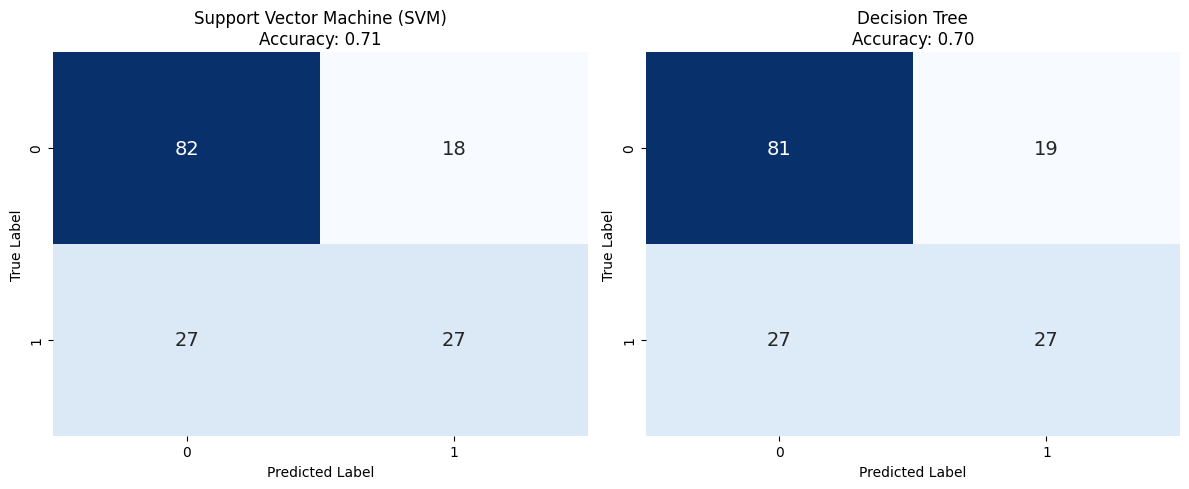

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for idx, (name, res) in enumerate(evaluation_results.items()):
  cm = confusion_matrix(y_test, res['y_pred'])
  sns.heatmap(
      cm,
      annot=True,
      fmt='d',
      cmap='Blues',
      ax=axes[idx],
      cbar=False,
      annot_kws={'size': 14},
  )
  axes[idx].set_title(f"{name}\nAccuracy: {res['accuracy']:.2f}")
  axes[idx].set_xlabel('Predicted Label')
  axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()